# Data Analysis and Visualisation

## Lab 7: Draw the reviews

### Preliminaries

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### Part 1

#### Task 1: Set up, and the first histogram

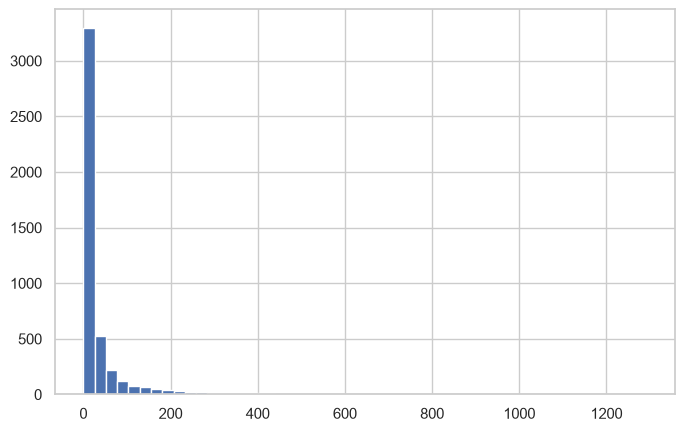

In [ ]:
# Load the table, parsing the dates
date_columns = ['last_scraped', 'calendar_last_scraped', 'first_review', 'last_review']
listings = pd.read_csv("data/listings_clean.csv", parse_dates=date_columns)

# Same theme as in the lecture.
sns.set_theme(style="whitegrid")

# Draw a histogram with pure matplotlib
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(listings["number_of_reviews"], bins=50)
plt.show()

We can see one very tall bar on the left and a thin tail to 1293, but no title and no axis names.

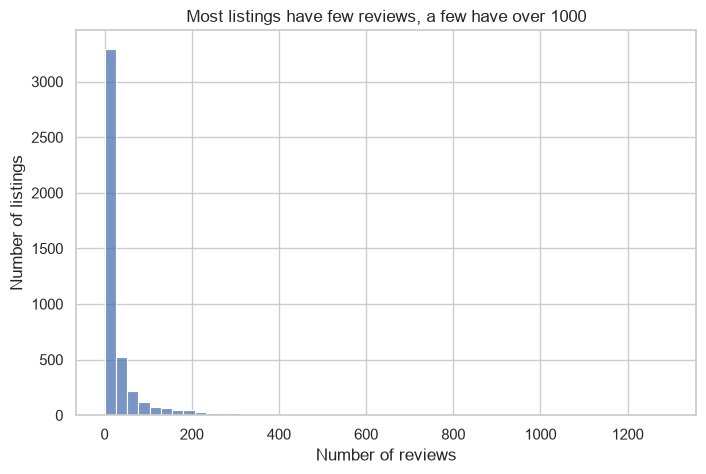

In [ ]:
# Draw the same diagram with Seaborn
fig, ax = plt.subplots(figsize=(8, 5))
sns.histplot(data=listings, x="number_of_reviews", bins=50, ax=ax)
ax.set_title("Most listings have few reviews, a few have over 1000")
ax.set_xlabel("Number of reviews")
ax.set_ylabel("Number of listings")
plt.show()

Seaborn: same shape, cleaner look, and we add a title and axis names.

#### Task 2: Mean, median and the fences

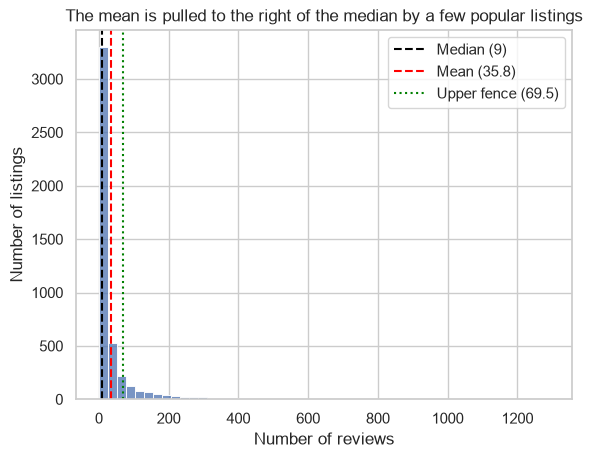

In [ ]:
reviews = listings["number_of_reviews"]

# Median, mean and the upper fence
median = reviews.median()
mean = reviews.mean()
q1, q3 = reviews.quantile(0.25), reviews.quantile(0.75)
upper = q3 + 1.5 * (q3 - q1)

# The histogram again, with one vertical line for each number.
fig, ax = plt.subplots()

sns.histplot(data=listings, x="number_of_reviews", bins=50, ax=ax)

ax.axvline(median, color="black", linestyle="--", label=f"Median ({median:.0f})")
ax.axvline(mean, color="red", linestyle="--", label=f"Mean ({mean:.1f})")
ax.axvline(upper, color="green", linestyle=':', label=f"Upper fence ({upper:.1f})")

ax.set_title("The mean is pulled to the right of the median by a few popular listings")
ax.set_xlabel("Number of reviews")
ax.set_ylabel("Number of listings")
ax.legend()

plt.show()

The fence (69.5) is furthest to the right, then the mean (35.8), then the median (9). The mean is to the right of the median because the few listings with very many reviews pull it.

#### Task 3: With and without the outliers

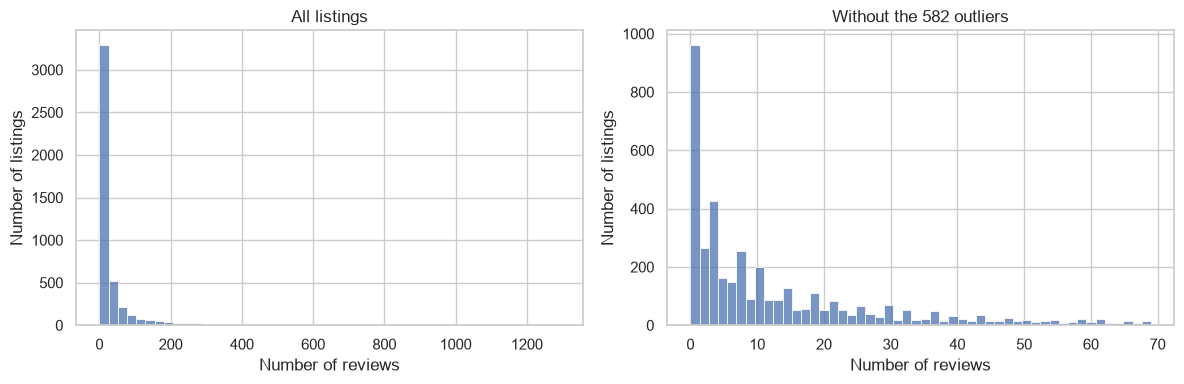

In [ ]:
# Mark the outliers in a dedicated column
listings["reviews_outlier"] = listings["number_of_reviews"] > upper
n_outliers = listings["reviews_outlier"].sum()

# Draw two charts side-by-side: 
# one with all listings and the other without the outliers
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=listings, x="number_of_reviews", bins=50, ax=axes[0])
sns.histplot(data=listings[~listings["reviews_outlier"]], x="number_of_reviews", bins=50, ax=axes[1])

# Set the titles
axes[0].set_title("All listings")
axes[1].set_title(f"Without the {n_outliers} outliers")

for ax in axes:
    ax.set_xlabel("Number of reviews")
    ax.set_ylabel("Number of listings")

plt.tight_layout()

plt.show()

The right chart has nothing above 69 and a much shorter x-axis, so the shape of the 3992 other listings becomes visible: still mostly on the left, but with a clear slope. The long tail hid this.

#### Task 4: The boxplot

room_type
Entire home/apt     8.0
Private room       12.0
Name: number_of_reviews, dtype: float64


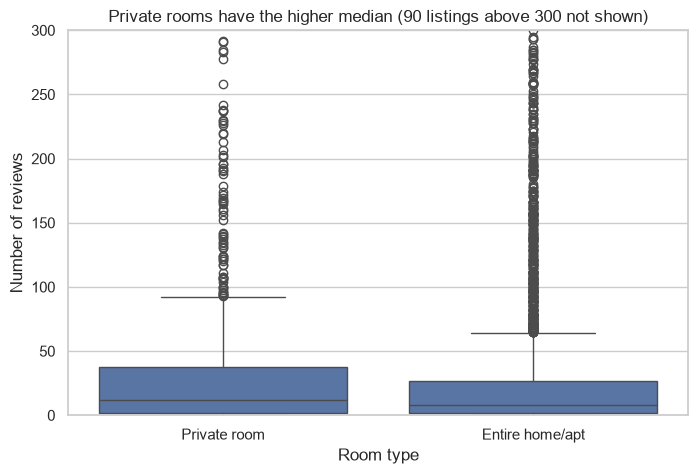

In [ ]:
# Only the two big room types.
big = listings[listings["room_type"].isin(["Entire home/apt", "Private room"])]

# Count what is cut away by the y-limit
limit = 300
n_above_big = (big["number_of_reviews"] > limit).sum()
print(big.groupby("room_type")["number_of_reviews"].median())

# Boxplot, with the y-axis limited to 0-300.
fig, ax = plt.subplots(figsize=(8, 5))

sns.boxplot(data=big, x="room_type", y="number_of_reviews", ax=ax)

ax.set_ylim(0, limit)
ax.set_title(f"Private rooms have the higher median ({n_above_big} listings above {limit} not shown)")
ax.set_xlabel("Room type")
ax.set_ylabel("Number of reviews")

plt.show()

Private room has the higher median (12 vs 8). Both boxes are low and the whiskers are short compared with the many dots above them.

#### Task 5: The bar charts

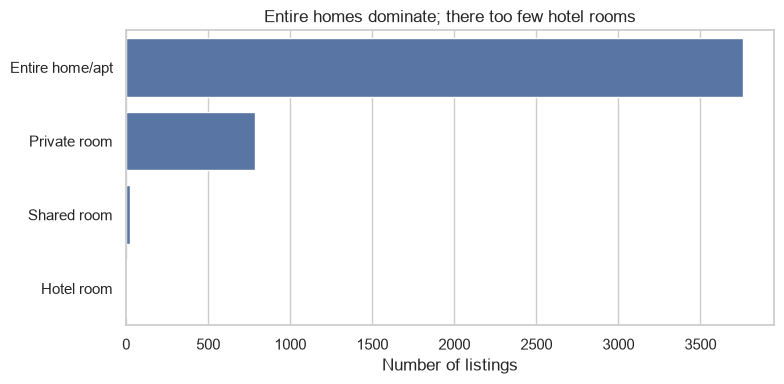

In [ ]:
# Number of listings per room type
order = listings["room_type"].value_counts().index

fig, ax = plt.subplots(figsize=(8, 4))

sns.countplot(data=listings, y="room_type", order=order, ax=ax)

ax.set_title("Entire homes dominate; there too few hotel rooms")
ax.set_xlabel("Number of listings")
ax.set_ylabel('')

plt.tight_layout()
plt.show()

In [ ]:
# Median reviews and number of listings per neighbourhood
by_area = (listings.groupby("neighbourhood_cleansed")["number_of_reviews"]
           .agg(["median", "count"])
           .sort_values("median", ascending=False)
           .reset_index()
)

# A label with the neighbourhood and the count in brackets.
by_area["label"] = by_area["neighbourhood_cleansed"] + " (" + by_area["count"].astype(str) + ")"

display(by_area)

,neighbourhood_cleansed,median,count,label
0,Södermalms,17.0,1145,Södermalms (1145)
1,Kungsholmens,12.0,420,Kungsholmens (420)
2,Norrmalms,10.0,469,Norrmalms (469)
3,Östermalms,9.0,297,Östermalms (297)
4,Älvsjö,8.5,214,Älvsjö (214)
5,Hägersten-Liljeholmens,8.0,464,Hägersten-Liljeholmens (464)
6,Skarpnäcks,8.0,221,Skarpnäcks (221)
7,Spånga-Tensta,7.0,89,Spånga-Tensta (89)
8,Enskede-Årsta-Vantörs,7.0,445,Enskede-Årsta-Vantörs (445)
9,Bromma,5.0,281,Bromma (281)


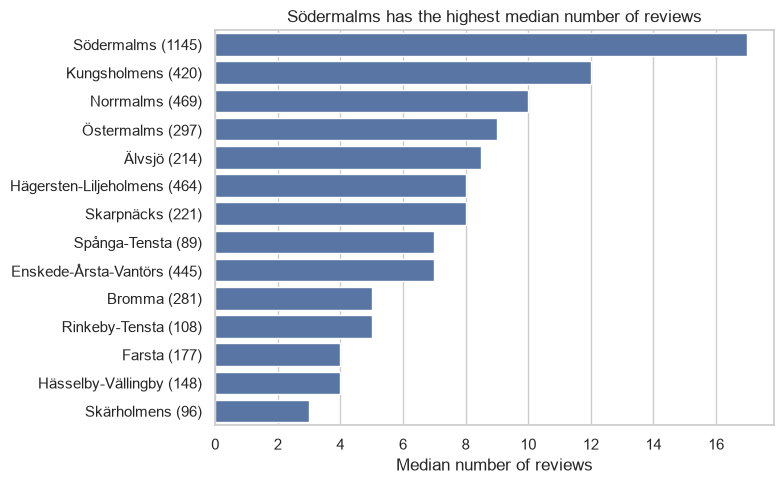

In [ ]:
# Make the bar chart
fig, ax = plt.subplots(figsize=(8, 5))

sns.barplot(data=by_area, x="median", y="label", ax=ax)

ax.set_title("Södermalms has the highest median number of reviews")
ax.set_xlabel("Median number of reviews")
ax.set_ylabel("")

plt.tight_layout()
plt.show()

Södermalms has the highest median of 17, and also the most listings (1145). Skärholmens has the lowest median of 3.

#### Task 6: The scatter plot

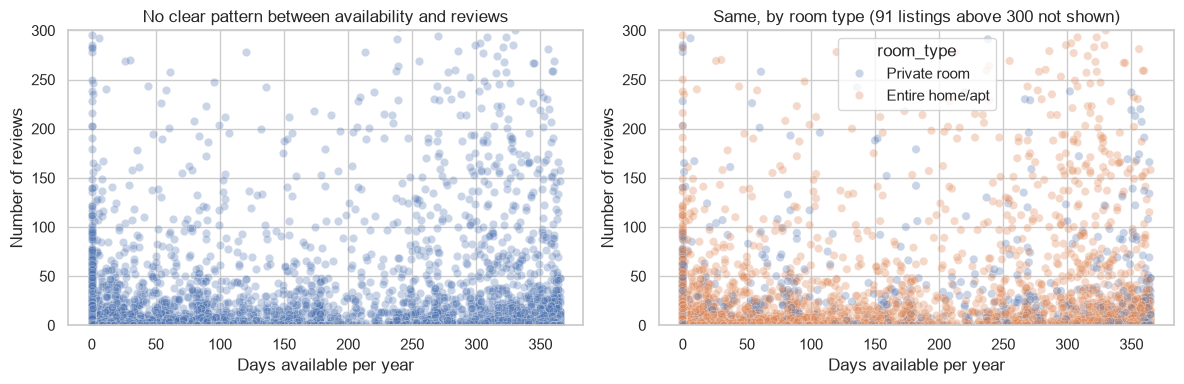

In [ ]:
n_above_all = (listings["number_of_reviews"] > limit).sum()

# Left: all listings. Right: coloured by room type, only the two big types.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.scatterplot(data=listings, x="availability_365", y="number_of_reviews", alpha=0.3, ax=axes[0])
sns.scatterplot(data=big, x="availability_365", y="number_of_reviews", hue="room_type", alpha=0.3, ax=axes[1])

axes[0].set_title("No clear pattern between availability and reviews")
axes[1].set_title(f"Same, by room type ({n_above_all} listings above {limit} not shown)")

for ax in axes:
    ax.set_ylim(0, limit)
    ax.set_xlabel("Days available per year")
    ax.set_ylabel("Number of reviews")

plt.tight_layout()
plt.show()

A cloud of dots, densest at the bottom, spread over the whole x-axis. There is no line or slope, which fits the weak correlation of 0.18 (from Lab 6). The two room types overlap a lot.